## NPIPE data vs $C_\ell$ with different $\xi$ and $\tau$


In [1]:
import numpy as np, local, os, tqdm, sys

from astropy.io import fits
import matplotlib.pyplot as plt

dir_pyrefclass = '//Users/salvatoresamuelesirletti/pyrefCLASS' # directory of pyrefCLASS
outroot = '/Users/salvatoresamuelesirletti/Desktop/Work/GitHub_projects/biref_iso_inject/biref_iso_inject/output/'


sys.path.append(dir_pyrefclass)
import pyrefCLASS as rot

import importlib
importlib.reload(rot)

import emcee
import corner


%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from matplotlib import colors
from matplotlib import rc
rc('text',usetex=True)
rc('font',**{'family':'serif','serif':['Computer Modern']})
plt.rcParams['figure.figsize'] = [9,7]  # Adjust the size as needed for the plots
from mpl_toolkits.mplot3d import Axes3D

In [6]:
# Define the function to load NPIPE data and load the data

data_path = '/Users/salvatoresamuelesirletti/lollipop_data/planck_2020/lollipop/'

def data_npipe(Dl=False, lmax=30, spec='all'):
    lb   = np.linspace(2, lmax, lmax - 1)
    nbin = lmax - 1
    lfac = lb * (lb + 1) / 2 / np.pi if Dl else np.ones(nbin)

    cldat = np.loadtxt(os.path.join(data_path, 'cl_lolEB_NPIPE.dat'), unpack=True)[1:4, :nbin] * lfac[None, :]
    clcov = fits.getdata(os.path.join(data_path, 'clcov_lolEB_NPIPE.fits'))
    nell  = len(clcov) // 3

    if spec == 'EE':
        cl = cldat[0]
        cov = clcov[0:nbin, 0:nbin]
    elif spec == 'BB':
        cl = cldat[1]
        cov = clcov[nell:nell+nbin, nell:nell+nbin]
    elif spec == 'EB':
        cl = cldat[2]
        cov = clcov[2*nell:2*nell+nbin, 2*nell:2*nell+nbin]
    elif spec == 'all':
        cl   = cldat.copy()
        cbcov = np.zeros((3*nbin, 3*nbin))
        for t1 in range(3):
            for t2 in range(3):
                cbcov[t1*nbin:(t1+1)*nbin, t2*nbin:(t2+1)*nbin] = \
                    clcov[t1*nell:t1*nell+nbin, t2*nell:t2*nell+nbin]
        cov = cbcov
    else:
        raise ValueError(f"spec='{spec}' not valid.")

    
    if Dl:
        if spec == 'all':
            lfac_all = np.tile(lfac, 3)
            cov = cov * np.outer(lfac_all, lfac_all)
        else:
            cov = cov * np.outer(lfac, lfac)

    vcl  = cov.diagonal()
    icov = np.linalg.inv(cov)
    
    
    if spec == 'all':
        scl = np.sqrt(vcl.reshape(-1, nbin))
    else:
        scl = np.sqrt(vcl)
        
    return lb, cl, scl, icov, vcl

lb, Dl_EE_obs, scl_EE, icov_EE, vcl_EE = data_npipe(Dl=True, lmax=30, spec='EE')

#lb, Dl_TE_obs, scl_TE, icov_TE, vcl_TE = data_npipe(Dl=True, lmax=30, spec='ET')

lb, Dl_BB_obs, scl_BB, icov_BB, vcl_BB = data_npipe(Dl=True, lmax=30, spec='BB')

lb, Dl_EB_obs, scl_EB, icov_EB, vcl_EB = data_npipe(Dl=True, lmax=30, spec='EB')


In [7]:
# Load CLASS-computed Power Spectra

lcl_test1_hp = np.loadtxt(outroot+'/hp/inject_tau0.054_logm-30.5_xi0_N10000_cl.dat',unpack=True,max_rows=3000)
lcl_test2_hp = np.loadtxt(outroot+'/hp/inject_tau0.08986_logm-30.5_xi0_N10000_cl.dat',unpack=True,max_rows=3000)

# Load the PS computed with the MCMC best fit parameters
best_fit_MCMC = np.loadtxt(outroot+'/hp/inject_tau0.08986_logm-30.5_xi0.0113_N10000_cl.dat',unpack=True,max_rows=3000)


TCMB_muK = 2.7255e6   # µK # CLASS saves the dimensionless total [l(l+1)/2pi] C_l's. To have the spectra in \muK^2, we need to multiply by TCMB_muK**2


/var/folders/jc/kky54qz15j50ck9_kzrzk_d80000gn/T/ipykernel_54743/3089138987.py:3: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=3000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  lcl_test1_hp = np.loadtxt(outroot+'/hp/inject_tau0.054_logm-30.5_xi0_N10000_cl.dat',unpack=True,max_rows=3000)
/var/folders/jc/kky54qz15j50ck9_kzrzk_d80000gn/T/ipykernel_54743/3089138987.py:4: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=3000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achiev

(-0.05, 0.11)

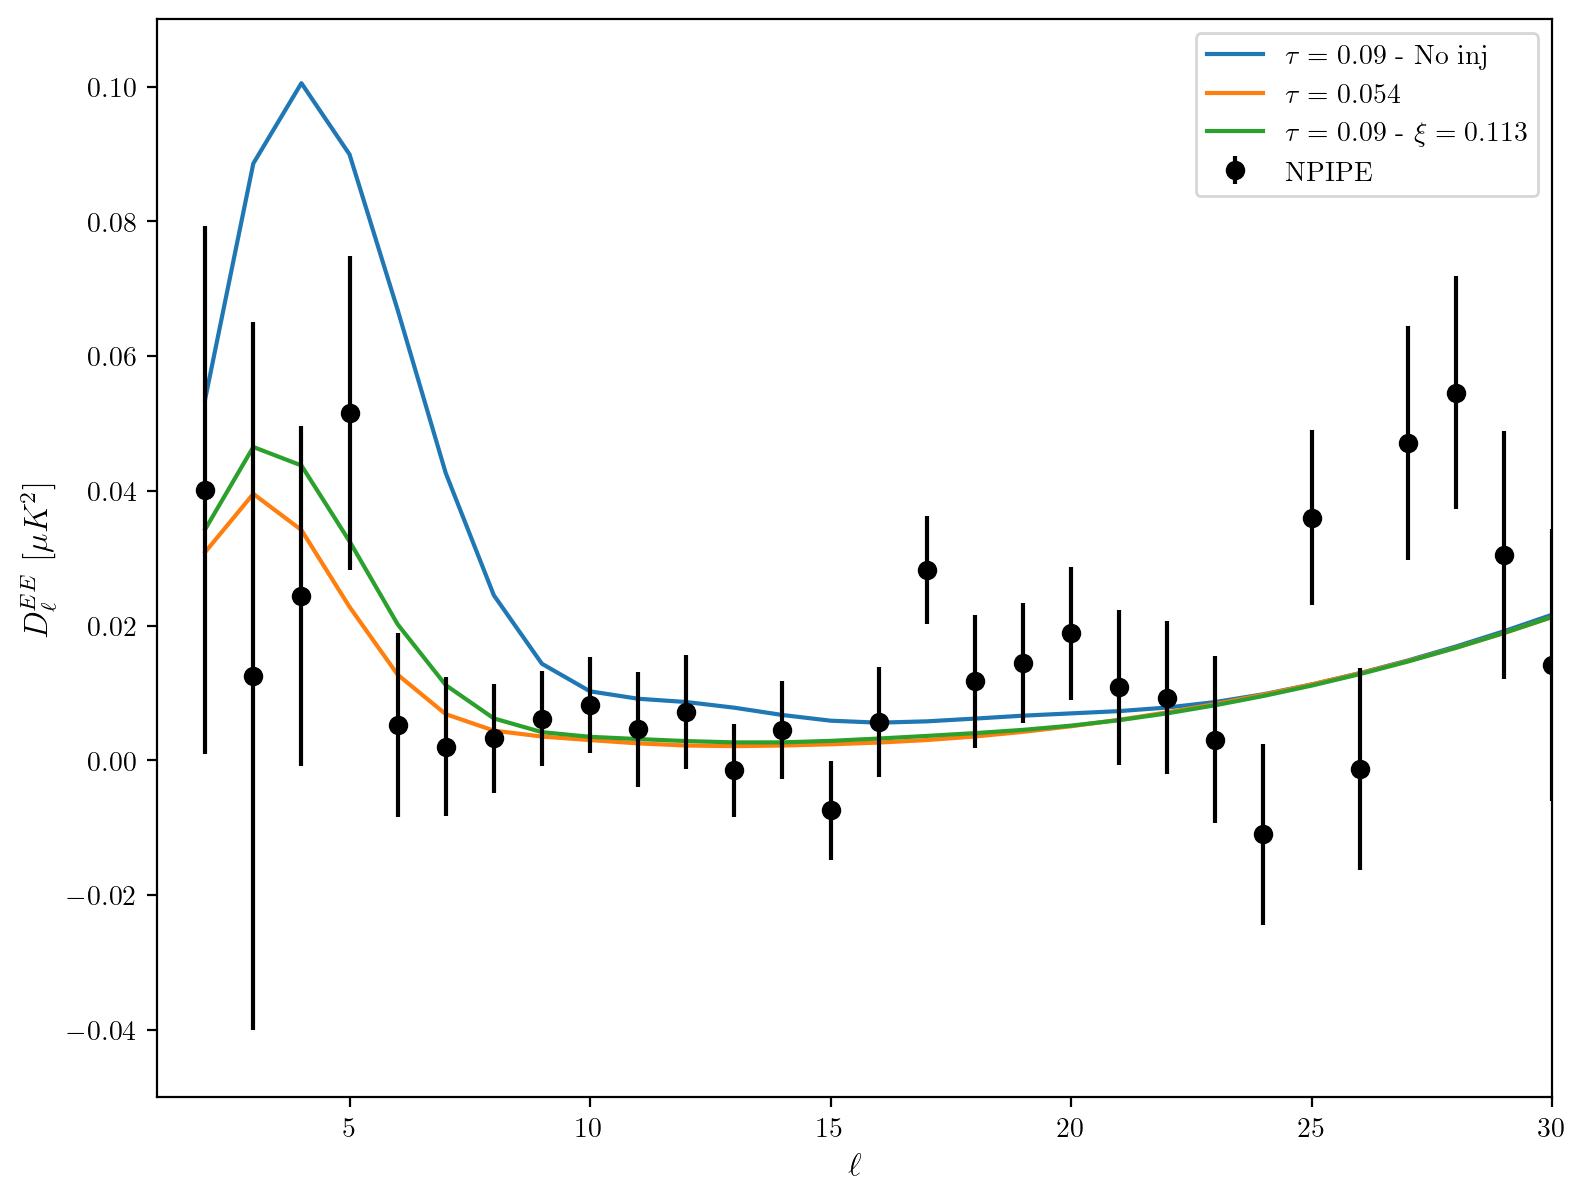

In [8]:
# CLASS vs OBS Power Spectra
## EE
plt.plot(lcl_test2_hp[0][:30], lcl_test2_hp[2][:30] * TCMB_muK**2, label=r'$\tau = 0.09$ - No inj')
plt.plot(lcl_test1_hp[0][:30], lcl_test1_hp[2][:30] * TCMB_muK**2, label=r'$\tau = 0.054$')
plt.plot(best_fit_MCMC[0][:], best_fit_MCMC[2][:] * TCMB_muK**2, label=r'$\tau = 0.09$ - $\xi = 0.113$') 

plt.errorbar(lb, Dl_EE_obs, yerr=scl_EE, fmt='o', color='k', label='NPIPE')

plt.xlabel(r'$\ell$', fontsize=12)
plt.ylabel(r'$D^{EE}_{\ell} \,\, [\mu K^2]$', fontsize=12)

plt.legend()

plt.xlim(1, 30)
plt.ylim(-0.05, 0.11)

# plt.show()



(1.0, 30.0)

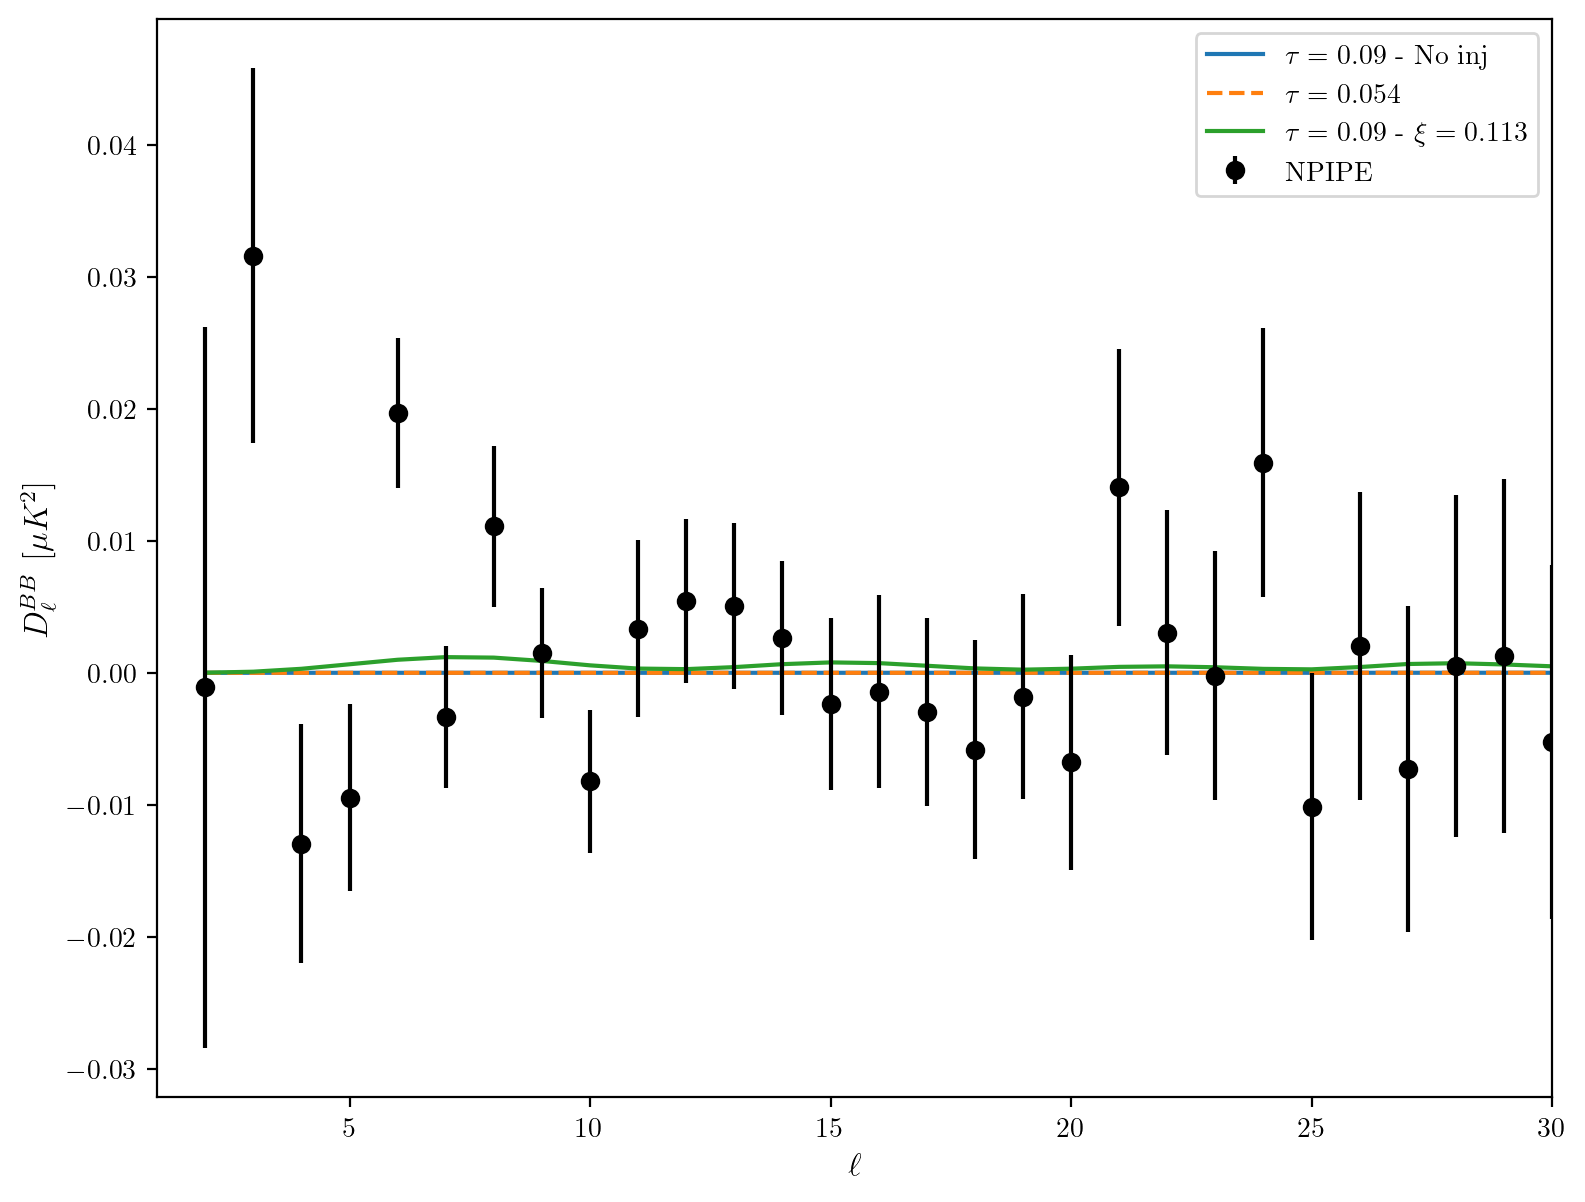

In [9]:
## BB
plt.plot(lcl_test2_hp[0][:30], lcl_test2_hp[4][:30] * TCMB_muK**2, label=r'$\tau = 0.09$ - No inj')
plt.plot(lcl_test1_hp[0][:30], lcl_test1_hp[4][:30] * TCMB_muK**2, label=r'$\tau = 0.054$', ls='--')
plt.plot(best_fit_MCMC[0][:], best_fit_MCMC[4][:] * TCMB_muK**2, label=r'$\tau = 0.09$ - $\xi = 0.113$') 

plt.errorbar(lb, Dl_BB_obs, yerr=scl_BB, fmt='o', color='k', label='NPIPE')

plt.xlabel(r'$\ell$', fontsize=12)
plt.ylabel(r'$D^{BB}_{\ell} \,\, [\mu K^2]$', fontsize=12)

plt.legend()

plt.xlim(1, 30)
#plt.ylim(-0.05, 0.11)

# plt.show()

(1.0, 30.0)

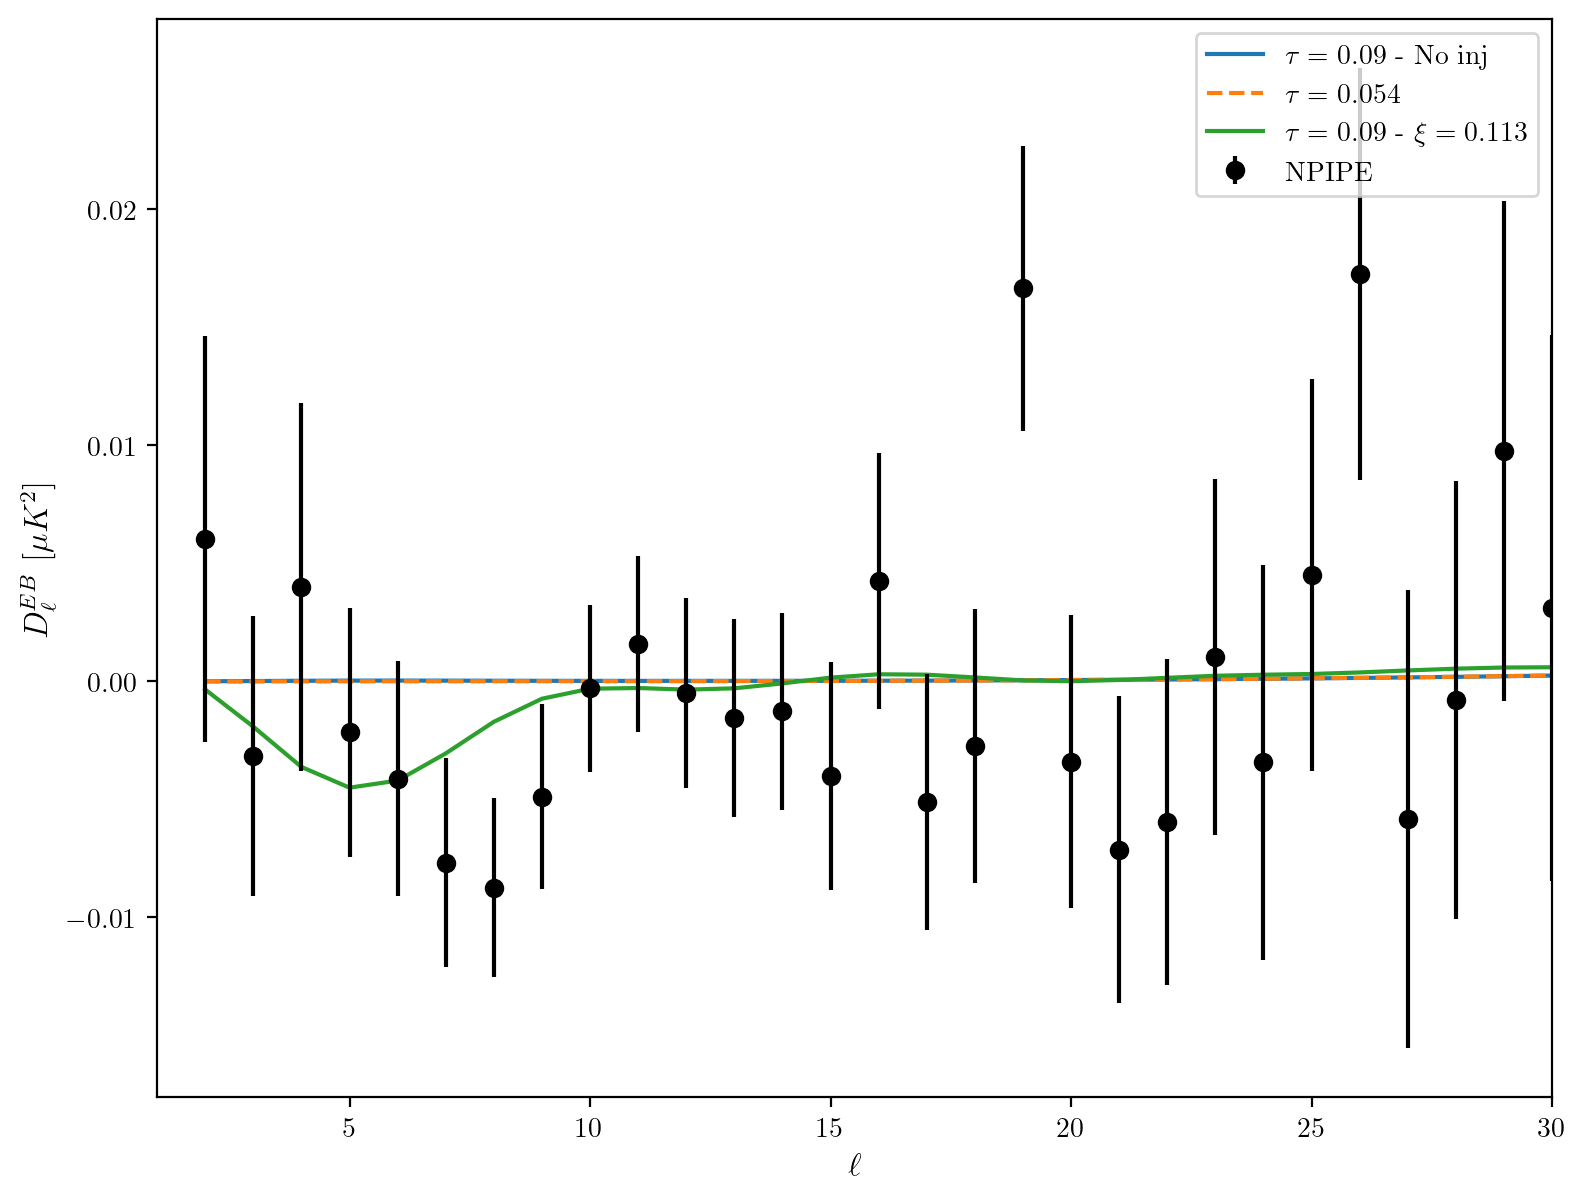

In [10]:
## EB
plt.plot(lcl_test2_hp[0][:30], lcl_test2_hp[5][:30] * TCMB_muK**2, label=r'$\tau = 0.09$ - No inj')
plt.plot(lcl_test1_hp[0][:30], lcl_test1_hp[5][:30] * TCMB_muK**2, label=r'$\tau = 0.054$', ls='--')
plt.plot(best_fit_MCMC[0][:], best_fit_MCMC[5][:] * TCMB_muK**2, label=r'$\tau = 0.09$ - $\xi = 0.113$') 

plt.errorbar(lb, Dl_EB_obs, yerr=scl_EB, fmt='o', color='k', label='NPIPE')

plt.xlabel(r'$\ell$', fontsize=12)
plt.ylabel(r'$D^{EB}_{\ell} \,\, [\mu K^2]$', fontsize=12)

plt.legend()

plt.xlim(1, 30)
#plt.ylim(-0.05, 0.11)

# plt.show()

In [11]:
print(f"Dl_EE_obs max:    {Dl_EE_obs.max():.3e}  µK²")
print(f"sqrt(vcl_EE) max: {np.sqrt(vcl_EE).max():.3e} ")
print(f"ratio:            {Dl_EE_obs.max() / np.sqrt(vcl_EE).max():.3f}  (must be ~O(1))")

Dl_EE_obs max:    5.457e-02  µK²
sqrt(vcl_EE) max: 5.253e-02 
ratio:            1.039  (must be ~O(1))


In [12]:
Dl_th = lcl_test1_hp[2][:29] * TCMB_muK**2  # Theoretical PS in µK²

delta = Dl_th - Dl_EE_obs
chi2  = delta @ icov_EE @ delta
ndof  = len(delta)
print(f"chi2 = {chi2:.2f}")
print(f"ndof = {ndof}")
print(f"chi2/ndof = {chi2/ndof:.2f}  (~1 if everything is correct)")

chi2 = 38.37
ndof = 29
chi2/ndof = 1.32  (~1 if everything is correct)


## Comparison at high ell, up to $\ell_{\rm max} = 2500$ 

In [13]:
lensed = False

if lensed:
    lcl_test3_hp = np.loadtxt(outroot+'hp/inject_tau0.08986_logm-30.5_xi0_N10000lmax2500_cl_lensed.dat',unpack=True,max_rows=3000)
    lcl_test4_hp = np.loadtxt(outroot+'hp/inject_tau0.054_logm-30.5_xi0_N10000lmax2500_cl_lensed.dat',unpack=True,max_rows=3000)
    lcl_test5_hp = np.loadtxt(outroot+'hp/inject_tau0.08986_logm-30.5_xi0.0113_N10000lmax2500_cl_lensed.dat',unpack=True,max_rows=3000)
else:
    lcl_test3_hp = np.loadtxt(outroot+'hp/inject_tau0.08986_logm-30.5_xi0_N10000lmax2500_cl.dat',unpack=True,max_rows=3000)
    lcl_test4_hp = np.loadtxt(outroot+'hp/inject_tau0.054_logm-30.5_xi0_N10000lmax2500_cl.dat',unpack=True,max_rows=3000)
    lcl_test5_hp = np.loadtxt(outroot+'hp/inject_tau0.08986_logm-30.5_xi0.0113_N10000lmax2500_cl.dat',unpack=True,max_rows=3000)

/var/folders/jc/kky54qz15j50ck9_kzrzk_d80000gn/T/ipykernel_54743/1028690307.py:8: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=3000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  lcl_test3_hp = np.loadtxt(outroot+'hp/inject_tau0.08986_logm-30.5_xi0_N10000lmax2500_cl.dat',unpack=True,max_rows=3000)
/var/folders/jc/kky54qz15j50ck9_kzrzk_d80000gn/T/ipykernel_54743/1028690307.py:9: UserWarning: Input line 1 contained no data and will not be counted towards `max_rows=3000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can 

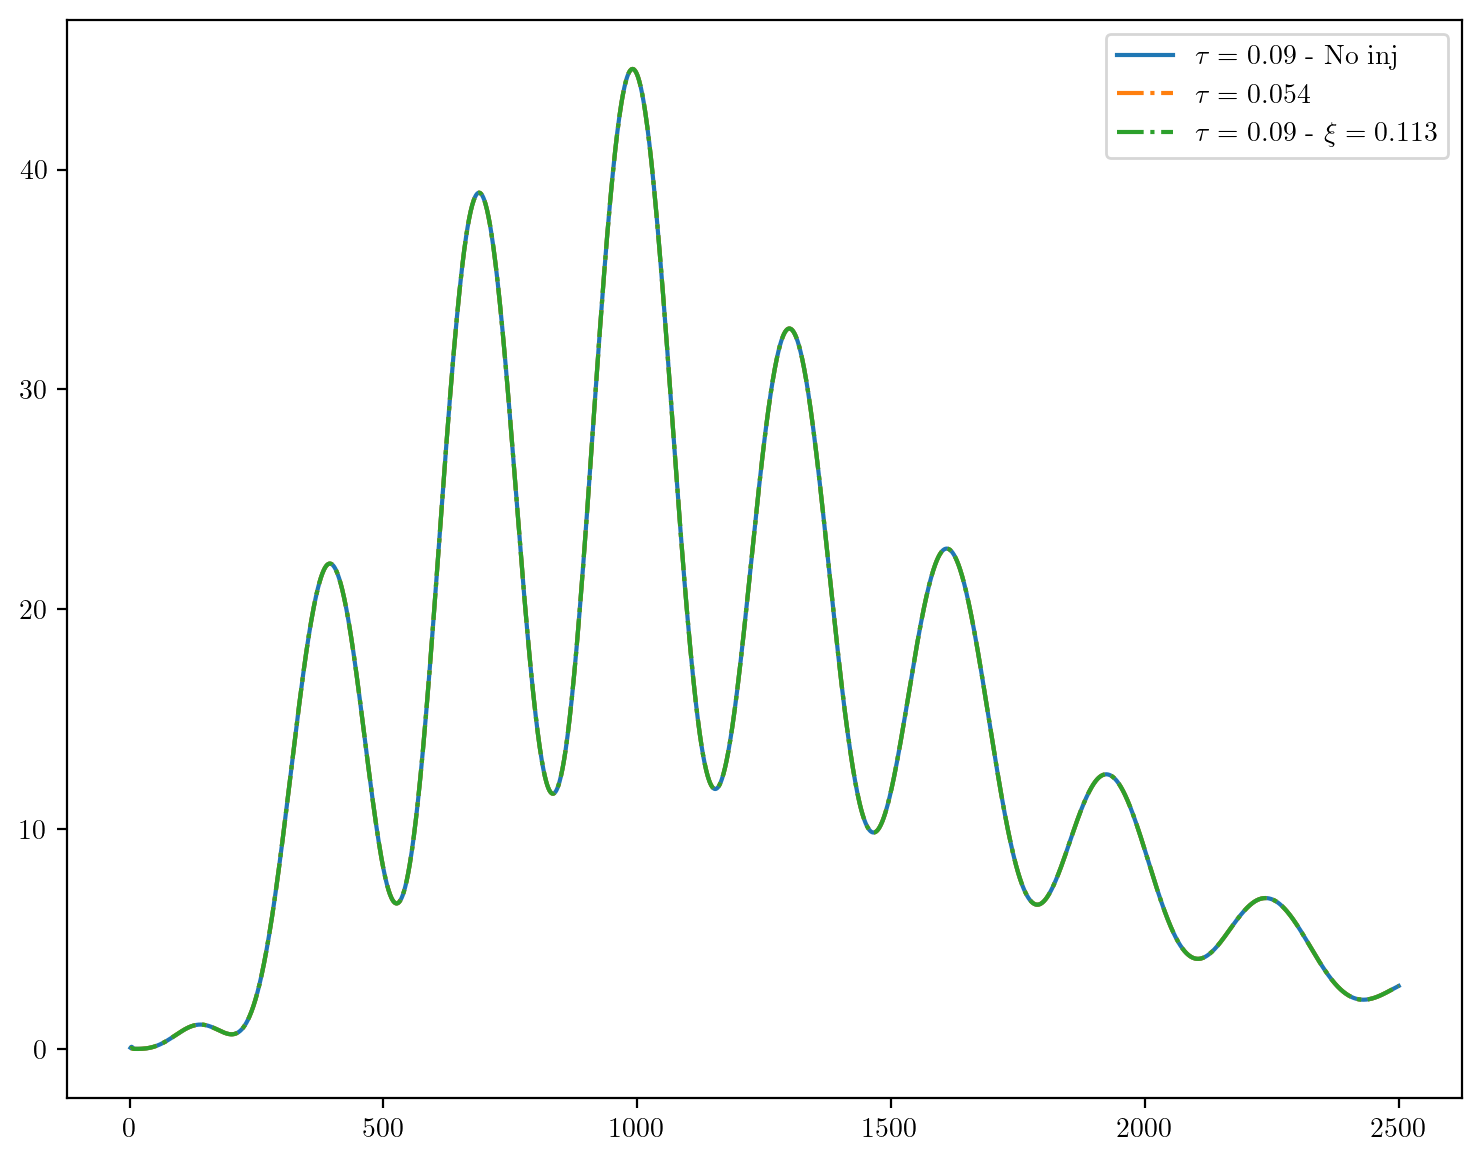

In [14]:
plt.plot(lcl_test3_hp[0][:], lcl_test3_hp[2][:] * TCMB_muK**2, label=r'$\tau = 0.09$ - No inj')
plt.plot(lcl_test4_hp[0][:], lcl_test4_hp[2][:] * TCMB_muK**2, label=r'$\tau = 0.054$', ls='-.')
plt.plot(lcl_test5_hp[0][:], lcl_test5_hp[2][:] * TCMB_muK**2, label=r'$\tau = 0.09$ - $\xi = 0.113$', ls='-.')
#plt.ylim(-0.02, 0.02)
plt.legend()